# CNN sur Fashion-MNIST

In [ ]:
# Colab : monte le Drive et se place dans le repo
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/early-dropout
#!git pull

Mounted at /content/drive
/content/drive/MyDrive/early-dropout


In [ ]:
import os, glob, time, importlib
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

import config, models, train
importlib.reload(config); importlib.reload(models); importlib.reload(train)
from config import BATCH, P, EARLY_GRID
from models import cnn
from train import entrainer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
tr = datasets.FashionMNIST("./data", train=True, download=True)
te = datasets.FashionMNIST("./data", train=False, download=True)
Xtr = tr.data.float().unsqueeze(1) / 255      # (N, 1, 28, 28) : on garde la forme d'image pour le CNN
Xte = te.data.float().unsqueeze(1) / 255
ytr, yte = tr.targets, te.targets

# même split de validation que pour le MLP
perm = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))
Xva, yva = Xtr[perm[:10000]], ytr[perm[:10000]]
Xtr, ytr = Xtr[perm[10000:]], ytr[perm[10000:]]

# normalisation avec les stats du train uniquement
mu, sd = Xtr.mean(), Xtr.std()
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd

data = dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)
data = {k: v.to(device) for k, v in data.items()}       # tout sur le GPU
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [ ]:
CADRE = "cnn_fmnist"
OUT = "resultats"

## Calibration : trouver un régime de sous-apprentissage
On compare sans dropout et dropout classique. delta = acc val (dropout classique) - acc val (sans dropout) : si delta < 0 le modèle sous-apprend, c'est ce qu'on cherche.

In [ ]:
CALIB_LARGEURS = [4, 8, 16]
CALIB_EPOCHS = [10, 20, 50]
CALIB_GRID = [0, 1]          # 0 = sans dropout, 1 = dropout classique
CALIB_SEEDS = [0, 1]

for L in CALIB_LARGEURS:
    for E in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{L}_e{E}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = cnn(1, 10, largeur=L)
                model.to(device)
                hist = entrainer(model, opt, data, E, t_early=round(frac * E), p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=L, epochs=E, frac=frac, seed=seed).to_csv(fichier, index=False)

In [ ]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_LARGEURS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_acc"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_acc")
t["delta"] = (t[1] - t[0]) * 100                         # dropout classique - sans dropout, en points
tab = t.groupby(["width", "epochs"]).agg(
    acc_sans_dropout=(0, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["sous_apprentissage"] = tab.delta_max <= -0.5         # toutes les seeds perdent au moins 0.5 pt
tab.round(3)

acc_sans_dropout  delta_moy  delta_min  delta_max  \
width epochs                                                      
4     10                 0.804     -1.436     -2.030     -0.842   
      20                 0.840     -0.645     -1.360      0.070   
      50                 0.876     -1.780     -2.420     -1.140   
8     10                 0.860     -0.966     -1.566     -0.366   
      20                 0.889     -0.488     -0.960     -0.136   
      50                 0.908      0.102      0.098      0.106   
16    10                 0.887     -0.003     -0.278      0.272   
      20                 0.911      0.021     -0.190      0.232   
      50                 0.915      0.904      0.642      1.166   

              sous_apprentissage  
width epochs                      
4     10                    True  
      20                   False  
      50                    True  
8     10                   False  
      20                   False  
      50                   False  
16    10                   False  
      20                   False  
      50                   False

On a une vraie carte des régimes pour le CNN. Plus le modèle est petit, plus le dropout standard le pénalise. Plus il est gros et entraîné longtemps, plus le dropout l’aide. C’est exactement la logique de la Fig. 5 du papier, et la largeur 16 a 50 epochs joue le rôle du MLP de largeur 64 : un cas de contrôle en surapprentissage. Cette carte fera une très bonne figure pour le rapport

On retient 20 epochs et 8 de largeur car ce modele est en sous_apprentissage avec une accuracy correcte. Ensuite on lance la grille complète comme pour le MLP.

In [ ]:
LARGEUR = 4
EPOCHS = 50
SEEDS = [0, 1, 2, 3, 4]

for frac in EARLY_GRID:
    for seed in SEEDS:
        fichier = f"{OUT}/{CADRE}_w{LARGEUR}_e{EPOCHS}_frac{frac}_s{seed}.csv"
        if os.path.exists(fichier):
            continue
        torch.manual_seed(seed)
        model, opt = cnn(1, 10, largeur=LARGEUR)
        model.to(device)
        hist = entrainer(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS), p=P, batch=BATCH)
        hist.assign(cadre=CADRE, width=LARGEUR, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)

Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50
Epoch 50/50


In [ ]:
# gain par rapport à "sans dropout", seed par seed, avec IC à 95 % (Student, 5 seeds)
metriques = ["train_loss", "val_loss", "val_acc", "test_acc"]
fin = {}
for frac in EARLY_GRID:
    fin[frac] = pd.DataFrame(
        [pd.read_csv(f"{OUT}/{CADRE}_w{LARGEUR}_e{EPOCHS}_frac{frac}_s{s}.csv").tail(5)[metriques].mean() for s in SEEDS],
        index=SEEDS)

res = {}
for frac in EARLY_GRID:
    if frac == 0:
        continue
    d = fin[frac] - fin[0]
    d[["val_acc", "test_acc"]] *= 100                     # accuracy en points
    ic = 2.776 * d.std() / len(SEEDS) ** 0.5
    res[frac] = pd.concat([d.mean(), ic.add_prefix("ic_")])
pd.DataFrame(res).T.round(3)

,train_loss,val_loss,val_acc,test_acc,ic_train_loss,ic_val_loss,ic_val_acc,ic_test_acc
0.1,0.005,0.007,-0.408,-0.253,0.012,0.018,0.964,0.794
0.2,-0.006,-0.003,-0.114,0.051,0.011,0.016,0.846,0.776
0.3,-0.005,-0.002,-0.155,-0.015,0.013,0.018,1.024,0.807
0.5,0.004,0.004,-0.548,-0.120,0.007,0.012,0.786,0.761
1.0,0.037,0.025,-1.412,-1.109,0.022,0.019,1.177,1.015


In [ ]:
EPOCHS_LIST = [50]
T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}
ic = lambda x: T95[len(x)] * x.std() / len(x) ** 0.5

comp = []
for E in EPOCHS_LIST:
    d = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w{LARGEUR}_e{E}_frac*_s*.csv"))
    d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
    f = (d[d.epoch >= E - 5]
         .groupby(["frac", "seed"])[["train_loss", "val_acc", "test_acc"]].mean()
         .reset_index())
    b = f[f.frac == 0].set_index("seed")
    for col in ["train_loss", "val_acc", "test_acc"]:
        f[f"d_{col}"] = f[col].values - b.loc[f.seed, col].values
    f["epochs"] = E
    comp.append(f)
comp = pd.concat(comp)

tab = comp.groupby(["epochs", "frac"]).agg(
    gain_val=("d_val_acc", lambda x: 100 * x.mean()),
    ic_val=("d_val_acc", lambda x: 100 * ic(x)),
    gain_test=("d_test_acc", lambda x: 100 * x.mean()),
    ic_test=("d_test_acc", lambda x: 100 * ic(x)),
    d_train_loss=("d_train_loss", "mean"),
    ic_train_loss=("d_train_loss", ic),
)
tab.round(3)

gain_val  ic_val  gain_test  ic_test  d_train_loss  ic_train_loss
epochs frac                                                                   
50     0.0      0.000   0.000      0.000    0.000         0.000          0.000
       0.1     -0.408   0.966     -0.253    0.795         0.005          0.012
       0.2     -0.114   0.847      0.051    0.777        -0.006          0.011
       0.3     -0.155   1.025     -0.015    0.808        -0.005          0.013
       0.5     -0.548   0.787     -0.120    0.763         0.004          0.007
       1.0     -1.412   1.179     -1.109    1.016         0.037          0.022

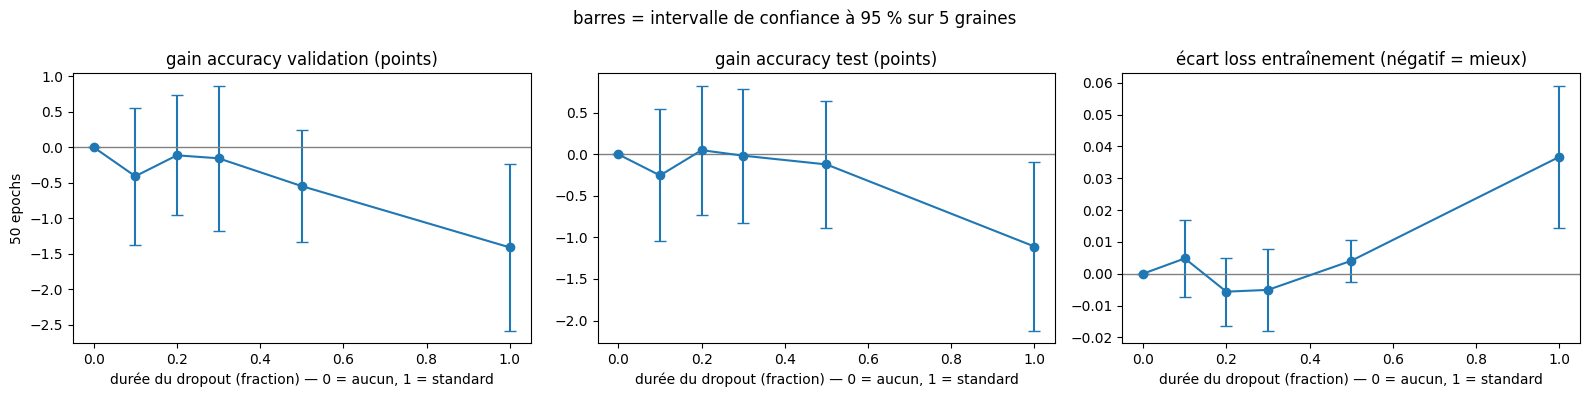

In [ ]:
fig, axes = plt.subplots(len(EPOCHS_LIST), 3, figsize=(16, 4 * len(EPOCHS_LIST)), sharey="col", squeeze=False)
for r, E in enumerate(EPOCHS_LIST):
    t = tab.loc[E]
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction) — 0 = aucun, 1 = standard")
axes[0, 0].set_title("gain accuracy validation (points)")
axes[0, 1].set_title("gain accuracy test (points)")
axes[0, 2].set_title("écart loss entraînement (négatif = mieux)")
plt.suptitle("barres = intervalle de confiance à 95 % sur 5 graines")
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive, userdata
drive.mount("/content/drive")
%cd /content/drive/MyDrive/early-dropout

!git config user.name "Felix-prjcts"
!git add cnn_fmnist.ipynb resultats/
!git commit -m "cnn run sur 50 epochs"

token = userdata.get("GITHUB_TOKEN")
!git push -q https://{token}@github.com/Felix-prjcts/early-dropout-study.git main 2>&1 | sed "s/{token}/***/g"